<a href="https://colab.research.google.com/github/zcflanzer/rcew-water-budget/blob/main/SCA_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# fSCA variables
Auhor: Zoe Flanzer\
Last edited: 5/22/2026\
Purpose of notebook: plot snow cover reconstruction data and calculate snow cover metrics.

In [1]:
## setting up notebook
# mount google drive
from google.colab import drive
drive.mount('/content/drive')

# importing relevant libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
import matplotlib.cm as cm
import matplotlib.colors as colors
from scipy.stats import spearmanr

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
## importing data
years = np.arange(2000, 2021) # years included

# data files
df_2000 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2000.csv')
df_2001 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2001.csv')
df_2002 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2002.csv')
df_2003 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2003.csv')
df_2004 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2004.csv')
df_2005 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2005.csv')
df_2006 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2006.csv')
df_2007 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2007.csv')
df_2008 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2008.csv')
df_2009 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2009.csv')
df_2010 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2010.csv')
df_2011 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2011.csv')
df_2012 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2012.csv')
df_2013 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2013.csv')
df_2014 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2014.csv')
df_2015 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2015.csv')
df_2016 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2016.csv')
df_2017 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2017.csv')
df_2018 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2018.csv')
df_2019 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2019.csv')
df_2020 = pd.read_csv('/content/drive/MyDrive/Thesis/Data/Snow/SCA/SCA_timeseries/SCA_timeseries_mean_2020.csv')

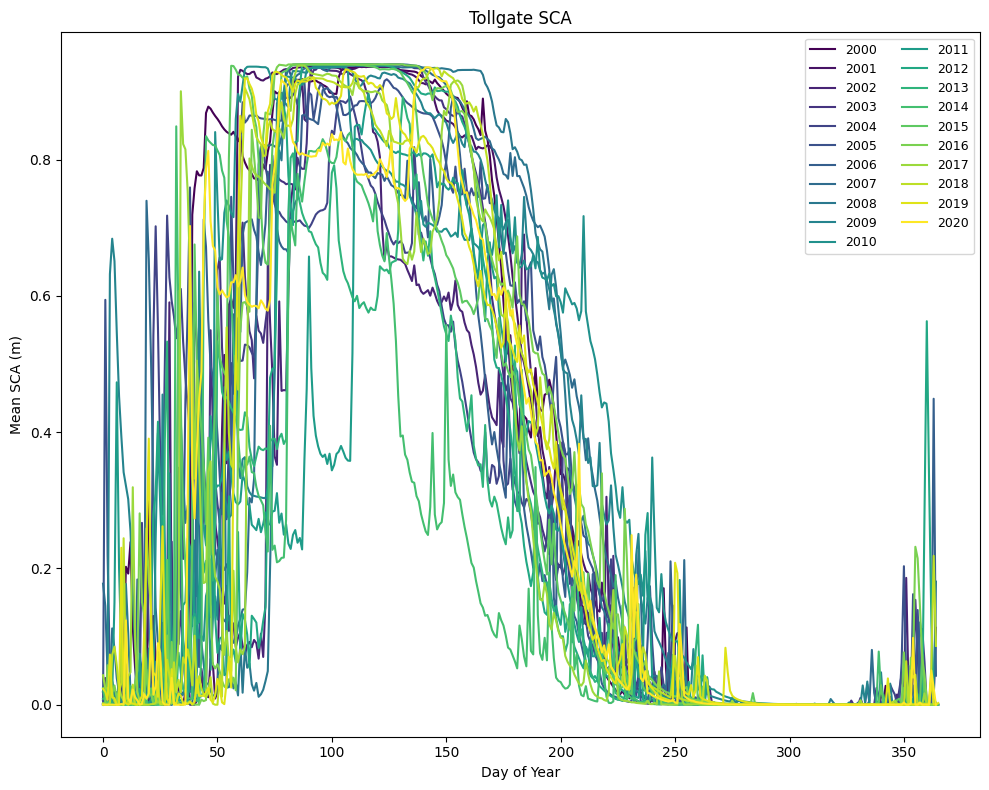

In [3]:
## plotting snow cover for all years
# creating color map
cmap = cm.viridis
norm = colors.Normalize(vmin=0, vmax=len(years)-1)

# looping through and plotting years
plt.figure(figsize=(10, 8))

for i, yr in enumerate(years):
    df = globals()[f"df_{yr}"]
    plt.plot(df['Day'],df['Mean_SCA'],color=cmap(norm(i)),label=str(yr))

# formatting
plt.legend(ncol=2, fontsize=9)
plt.xlabel("Day of Year")
plt.ylabel("Mean SCA (m)")
plt.title("Tollgate SCA")
plt.tight_layout()
plt.show()

In [4]:
## calculating relevant snow cover metrics
CONSEC = 1  # number of consecutive days required
rows = []

# looping through years
for yr in years:
    df = globals()[f"df_{yr}"]

    # calculating "peak" snow cover (if there are repeat days with the same value, then the first day)
    idx = df['Mean_SCA'].idxmax()
    max_sca = df.loc[idx, 'Mean_SCA']
    day_of_max = df.loc[idx, 'Day']

    # meltout day using dynamic 10% threshold
    THRESH = 0.10 * max_sca # threshold value
    after_peak = df.loc[idx+1:].reset_index(drop=True) # data after the peak
    low_dyn = after_peak['Mean_SCA'] < THRESH

    melt_day_dynamic = None
    run = 0
    for i, val in enumerate(low_dyn):
        if val:
            run += 1
        else:
            run = 0
        if run >= CONSEC:
            melt_day_dynamic = after_peak.loc[i, 'Day']
            break

    # meltout day with zero snow cover
    low_zero = after_peak['Mean_SCA'] <= 0

    melt_day_zero = None
    run = 0
    for i, val in enumerate(low_zero):
        if val:
            run += 1
        else:
            run = 0
        if run >= CONSEC:
            melt_day_zero = after_peak.loc[i, 'Day']
            break

    # melt slope (max SCA → 10% threshold)
    if melt_day_dynamic is not None and melt_day_dynamic > day_of_max:
        melt_duration = melt_day_dynamic - day_of_max
        melt_slope = max_sca / melt_duration
    else:
        melt_slope = np.nan

    # append results
    rows.append({
        "year": yr,
        "max_SCA_day": day_of_max,
        "max_SCA": max_sca,
        "dynamic_SCA_threshold": THRESH,
        "meltout_day_dynamic10pct": melt_day_dynamic,
        "meltout_day_zero": melt_day_zero,
        "melt_slope": melt_slope
    })

sca_summary = pd.DataFrame(rows).sort_values("year")

print(sca_summary)
# saving as csv
#sca_summary.to_csv("SCA_variables_summary.csv", index=False)

    year  max_SCA_day   max_SCA  dynamic_SCA_threshold  \
0   2000          117  0.936941               0.093694   
1   2001           95  0.936939               0.093694   
2   2002           92  0.935956               0.093596   
3   2003          100  0.939962               0.093996   
4   2004          108  0.892813               0.089281   
5   2005           81  0.933569               0.093357   
6   2006           98  0.905111               0.090511   
7   2007          126  0.939968               0.093997   
8   2008           86  0.939966               0.093997   
9   2009           98  0.937508               0.093751   
10  2010           65  0.936593               0.093659   
11  2011          116  0.897308               0.089731   
12  2012          102  0.939958               0.093996   
13  2013          131  0.891516               0.089152   
14  2014           32  0.848964               0.084896   
15  2015          107  0.939969               0.093997   
16  2016      

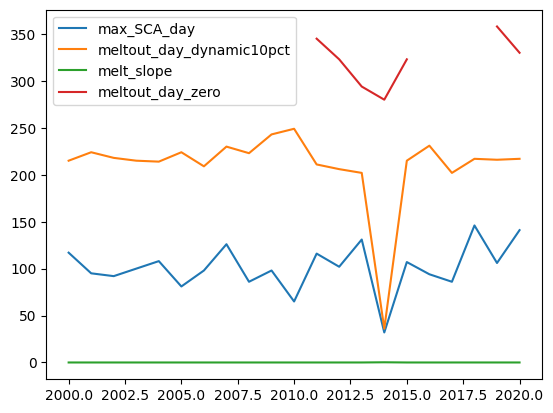

In [5]:
plt.plot(sca_summary['year'], sca_summary['max_SCA_day'])
plt.plot(sca_summary['year'], sca_summary['meltout_day_dynamic10pct'])
plt.plot(sca_summary['year'], sca_summary['melt_slope'])
plt.plot(sca_summary['year'], sca_summary['meltout_day_zero'])
plt.legend(["max_SCA_day", "meltout_day_dynamic10pct", "melt_slope", "meltout_day_zero"])
plt.show()

In [6]:
## testing if any variables are changing over time
vars_to_test = [
    "max_SCA_day",
    "max_SCA",
    "dynamic_SCA_threshold",
    "meltout_day_dynamic10pct",
    "meltout_day_zero",
    "melt_slope"
]

corr_rows = []

for var in vars_to_test:
    # drop rows with NaN
    df_clean = sca_summary.dropna(subset=[var])

    # spearman
    spear_rho, spear_p = spearmanr(df_clean["year"], df_clean[var])

    corr_rows.append({
        "variable": var,
        "spearman_rho": spear_rho,
        "spearman_p": spear_p
    })

sca_corr = pd.DataFrame(corr_rows)

print(sca_corr)

                   variable  spearman_rho  spearman_p
0               max_SCA_day      0.191033    0.406822
1                   max_SCA     -0.042857    0.853657
2     dynamic_SCA_threshold     -0.042857    0.853657
3  meltout_day_dynamic10pct     -0.177026    0.442692
4          meltout_day_zero      0.246202    0.417454
5                melt_slope      0.340260    0.131238
